In [1]:
import io
import math
import os
import random
import subprocess
import time
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from einops import rearrange
from einops.layers.torch import Rearrange

# ==========================================
# Strict Reproducibility / Determinism Setup
# ==========================================
SEED_VALUE = 42

# 1. Python & NumPy seeds
random.seed(SEED_VALUE)
np.random.seed(SEED_VALUE)

# 2. PyTorch CPU & GPU seeds
torch.manual_seed(SEED_VALUE)
torch.cuda.manual_seed(SEED_VALUE)
torch.cuda.manual_seed_all(SEED_VALUE)

# 3. CuDNN Determinism Settings
# Note: benchmark must be False and deterministic must be True 
# to guarantee identical outputs across multiple runs on a GPU.
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

# 4. Enforce strict deterministic algorithms in PyTorch
torch.use_deterministic_algorithms(True, warn_only=True)

In [2]:

# 1. Clone the repository into a temporary folder
repo_url = "https://github.com/Graham-Brady-Research-Group/AutoregressiveEnsemble_SpatioTemporal_Evolution.git"
temp_dir = "temp_repo_files"

if os.path.exists(temp_dir):
    subprocess.run(["rm", "-rf", temp_dir])

print("Cloning repository...")
subprocess.run(["git", "clone", repo_url, temp_dir])

# 2. Move all .py files from the cloned repo to your current working directory
py_files_moved = 0
for root, dirs, files in os.walk(temp_dir):
    # Skip the .git folder itself
    if ".git" in root:
        continue
    for file in files:
        if file.endswith(".py"):
            src_path = os.path.join(root, file)
            dest_path = file  # Saves directly to your current working directory

            # If there are duplicate filenames in subfolders, you can prefix them or just copy
            subprocess.run(["cp", src_path, dest_path])
            print(f"Downloaded/Copied: {file}")
            py_files_moved += 1

# 3. Clean up the temporary directory
subprocess.run(["rm", "-rf", temp_dir])
print(f"\nSuccessfully brought {py_files_moved} Python file(s) into your working directory!")

Cloning repository...


Cloning into 'temp_repo_files'...


Downloaded/Copied: dataprocessor_loadpathvar.py
Downloaded/Copied: loadpath_gen.py
Downloaded/Copied: utils.py
Downloaded/Copied: inference.py
Downloaded/Copied: unet_2d.py
Downloaded/Copied: main.py
Downloaded/Copied: viz_utils.py

Successfully brought 7 Python file(s) into your working directory!


In [3]:
def generate_pde_data(num_pdes=1000, time_steps=50, grid_points=128, device='cpu'):
    """
    Generates 1D Modified Shallow Water PDE trajectories efficiently 
    using fully vectorized PyTorch tensor operations.
    Returns: torch.Tensor of shape [num_pdes, time_steps, grid_points] (Height h)
    """
    # Fix: Use torch.arange instead of torch.linspace to mimic endpoint=False
    dx = (2 * np.pi) / grid_points
    x = torch.arange(0, grid_points, device=device) * dx

    t_max = 5.0
    dt_sim = 0.0001
    total_sim_steps = int(t_max / dt_sim) + 1
    save_every = max(1, total_sim_steps // time_steps)

    g = 9.81
    H = 1.0
    nu = 1e-4

    # 1. Initialize batch tensors [num_pdes, grid_points]
    h = H + torch.rand(num_pdes, grid_points, device=device) * 0.1 - 0.05
    u = torch.zeros(num_pdes, grid_points, device=device)

    # 2. Gaussian Forcing F(x) for each PDE trajectory:
    centers = torch.rand(num_pdes, 1, device=device) * (2 * np.pi)
    stds = torch.rand(num_pdes, 1, device=device) * 0.9 + 0.1       # Range: [0.1, 1.0]
    amplitudes = torch.rand(num_pdes, 1, device=device) * 0.8 + 0.1  # Max value < 1.0
    
    x_grid = x.unsqueeze(0)  # Shape: [1, grid_points]
    F = amplitudes * torch.exp(-((x_grid - centers) ** 2) / (2 * (stds ** 2))) # Shape: [num_pdes, grid_points]

    trajectory_h_list = []

    # Helper function for periodic shifts along the grid dimension
    def roll_tensor(tensor, shift):
        return torch.roll(tensor, shifts=shift, dims=1)

    # 3. Vectorized time integration loop
    for step in range(total_sim_steps):
        if step % save_every == 0 and len(trajectory_h_list) < time_steps:
            trajectory_h_list.append(h.clone())

        # First-order spatial derivatives (Central differences)
        du_dx = (roll_tensor(u, -1) - roll_tensor(u, 1)) / (2 * dx)
        dh_dx = (roll_tensor(h, -1) - roll_tensor(h, 1)) / (2 * dx)
        
        hu = h * u
        dhu_dx = (roll_tensor(hu, -1) - roll_tensor(hu, 1)) / (2 * dx)

        # Fourth-order hyperviscosity derivatives (\nabla^4)
        lap4_u = (roll_tensor(u, -2) - 4 * roll_tensor(u, -1) + 6 * u - 4 * roll_tensor(u, 1) + roll_tensor(u, 2)) / (dx ** 4)
        lap4_h = (roll_tensor(h, -2) - 4 * roll_tensor(h, -1) + 6 * h - 4 * roll_tensor(h, 1) + roll_tensor(h, 2)) / (dx ** 4)

        # Equations (16) & (17)
        du_dt = -u * du_dx - g * dh_dx - nu * lap4_u
        dh_dt = -H * du_dx - dhu_dx - nu * lap4_h + F

        # Forward Euler update
        u = u + dt_sim * du_dt
        h = h + dt_sim * dh_dt

    # Stack into [num_pdes, time_steps, grid_points]
    return torch.stack(trajectory_h_list[:time_steps], dim=1)

In [4]:
def prepare_training_pairs(pde_trajectories: torch.Tensor, history_steps: int = 10):
    X, Y = [], []
    num_samples, total_time, grid_size = pde_trajectories.shape

    for t in range(history_steps, total_time):
        x_seq = pde_trajectories[:, t - history_steps : t, :].permute(0, 2, 1)
        y_seq = pde_trajectories[:, t : t + 1, :].permute(0, 2, 1)
        X.append(x_seq)
        Y.append(y_seq)

    X = torch.cat(X, dim=0)
    Y = torch.cat(Y, dim=0)
    return X, Y

In [5]:
def plot_trajectory_summary(sample_idx, title_prefix, mse_val, mae_val, r2_val,
                            ground_truth_np, predicted_np, history_steps, grid_points):
    actual_sample = ground_truth_np[sample_idx]
    predicted_sample = predicted_np[sample_idx]

    fig = plt.figure(figsize=(15, 10))
    fig.suptitle(
        f"{title_prefix} (Sample #{sample_idx + 1})\n"
        f"MSE: {mse_val:.6f} | MAE: {mae_val:.6f} | R² Score: {r2_val:.4f}",
        fontsize=14, fontweight='bold'
    )

    # 1. Heatmap: Ground Truth
    ax1 = fig.add_subplot(2, 2, 1)
    im1 = ax1.imshow(actual_sample, aspect='auto', cmap='jet', origin='lower')
    ax1.set_title("Actual Ground Truth (Space-Time)")
    ax1.set_xlabel("Spatial Grid (x)")
    ax1.set_ylabel("Time Step (t)")
    ax1.axhline(y=history_steps - 0.5, color='black', linestyle='--', label=f'End of initial {history_steps} steps')
    fig.colorbar(im1, ax=ax1)

    # 2. Heatmap: FNO Auto-regressive Prediction
    ax2 = fig.add_subplot(2, 2, 2)
    im2 = ax2.imshow(predicted_sample, aspect='auto', cmap='jet', origin='lower')
    ax2.set_title("FNO Prediction (Auto-regressive)")
    ax2.set_xlabel("Spatial Grid (x)")
    ax2.set_ylabel("Time Step (t)")
    ax2.axhline(y=history_steps - 0.5, color='black', linestyle='--', label=f'End of initial {history_steps} steps')
    fig.colorbar(im2, ax=ax2)

    # 3. Absolute Error Heatmap
    ax3 = fig.add_subplot(2, 2, 3)
    error_sample = np.abs(actual_sample - predicted_sample)
    im3 = ax3.imshow(error_sample, aspect='auto', cmap='Reds', origin='lower')
    ax3.set_title("Absolute Error |Actual - Predicted|")
    ax3.set_xlabel("Spatial Grid (x)")
    ax3.set_ylabel("Time Step (t)")
    fig.colorbar(im3, ax=ax3)

    # 4. Snapshot profiles at specific future time steps
    ax4 = fig.add_subplot(2, 2, 4)
    x_axis = np.linspace(0, 1, grid_points)
    time_snapshots = [history_steps + 2, 25, 45]  # Time steps to view cross-sections

    for t_snap in time_snapshots:
        ax4.plot(x_axis, actual_sample[t_snap], label=f"Actual (t={t_snap})", linestyle='--')
        ax4.plot(x_axis, predicted_sample[t_snap], label=f"Pred (t={t_snap})")

    ax4.set_title("Spatial Profile Snapshots")
    ax4.set_xlabel("Spatial Grid (x)")
    ax4.set_ylabel("u(x, t)")
    ax4.legend(loc='upper right', fontsize='small')
    ax4.grid(True)

    plt.tight_layout()
    plt.show()

In [6]:


def exists(x):
    return x is not None

def default(val, d):
    if exists(val):
        return val
    return d() if callable(d) else d


def conv_forward_pass_unet(model, x_batch, history_steps, ip_time_dim, device):
    batch_size = x_batch.shape[0]
    H, W = 8, 16
    x_latest = x_batch[:, :, -1] if x_batch.ndim == 3 else x_batch
    x_spatial = x_latest.view(batch_size, 1, H, W).repeat(1, 3, 1, 1)
    t_cond = x_batch[:, 0, :ip_time_dim] if x_batch.ndim == 3 else torch.zeros(batch_size, ip_time_dim, device=device)
    return model(x_spatial, t_cond)

## Fast Upsample & Downsample
def Upsample(dim, dim_out = None):
    return nn.Sequential(
        nn.Upsample(scale_factor = 2, mode = 'nearest'),
        nn.Conv2d(dim, default(dim_out, dim), 3, padding = 1)
    )

def Downsample(dim, dim_out = None):
    return nn.Sequential(
        Rearrange('b c (h p1) (w p2) -> b (c p1 p2) h w', p1 = 2, p2 = 2),
        nn.Conv2d(dim * 4, default(dim_out, dim), 1)
    )


## Fast Spectral Convolution (FNO) for O(N log N) Global Context
class FastSpectralConv2d(nn.Module):
    def __init__(self, in_channels, out_channels, modes1=8, modes2=8):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.modes1 = modes1
        self.modes2 = modes2

        scale = 1.0 / (in_channels * out_channels)
        self.weights1 = nn.Parameter(
            scale * torch.rand(in_channels, out_channels, self.modes1, self.modes2, dtype=torch.cfloat)
        )
        self.weights2 = nn.Parameter(
            scale * torch.rand(in_channels, out_channels, self.modes1, self.modes2, dtype=torch.cfloat)
        )

    def forward(self, x):
        batchsize = x.shape[0]
        x_ft = torch.fft.rfft2(x)

        out_ft = torch.zeros(
            batchsize, self.out_channels, x.size(-2), x.size(-1) // 2 + 1,
            dtype=torch.cfloat, device=x.device
        )

        m1 = min(self.modes1, x_ft.size(-2))
        m2 = min(self.modes2, x_ft.size(-1))

        out_ft[:, :, :m1, :m2] = torch.einsum(
            "bixy,ioxy->boxy", x_ft[:, :, :m1, :m2], self.weights1[:, :, :m1, :m2]
        )
        out_ft[:, :, -m1:, :m2] = torch.einsum(
            "bixy,ioxy->boxy", x_ft[:, :, -m1:, :m2], self.weights2[:, :, :m1, :m2]
        )

        return torch.fft.irfft2(out_ft, s=(x.size(-2), x.size(-1)))


## Sinusoidal Positional Embedding
class SinusoidalPosEmb(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, x):
        device = x.device
        half_dim = self.dim
        emb = math.log(10000) / (half_dim - 1)
        emb = torch.exp(torch.arange(half_dim, device=device) * -emb)
        emb = x * emb[None, :]
        return torch.cat((emb.sin(), emb.cos()), dim=-1)


## Ultra-Fast Depthwise Separable ResNet Block
class FastResnetBlock(nn.Module):
    def __init__(self, dim, dim_out, *, time_emb_dim = None, groups = 8):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.SiLU(),
            nn.Linear(time_emb_dim, dim_out * 2)
        ) if exists(time_emb_dim) else None

        # Depthwise Separable Convolutions (drastically reduces FLOPs)
        self.conv1 = nn.Sequential(
            nn.Conv2d(dim, dim, 3, padding=1, groups=dim, bias=False),
            nn.Conv2d(dim, dim_out, 1, bias=False),
            nn.GroupNorm(groups if dim_out % groups == 0 else 1, dim_out),
            nn.SiLU()
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(dim_out, dim_out, 3, padding=1, groups=dim_out, bias=False),
            nn.Conv2d(dim_out, dim_out, 1, bias=False),
            nn.GroupNorm(groups if dim_out % groups == 0 else 1, dim_out),
            nn.SiLU()
        )
        self.res_conv = nn.Conv2d(dim, dim_out, 1) if dim != dim_out else nn.Identity()

    def forward(self, x, time_emb = None):
        scale_shift = None
        if exists(self.mlp) and exists(time_emb):
            time_emb = self.mlp(time_emb)
            time_emb = rearrange(time_emb, 'b c -> b c 1 1')
            scale, shift = time_emb.chunk(2, dim = 1)
            scale_shift = (scale, shift)

        h = self.conv1(x)
        if exists(scale_shift):
            h = h * (scale_shift[0] + 1) + scale_shift[1]
        h = self.conv2(h)
        return h + self.res_conv(x)


######### Ultra-Fast Drop-In UNet2D ##############
class Unet2D(nn.Module):
    def __init__(
        self,
        dim,
        init_dim = None,
        out_dim = None,
        dim_mults=(1, 2),  # Shallow and fast defaults
        channels = None,
        ip_time_dim = None,
        attn = None,
        self_condition = False,
        resnet_block_groups = 8,
        learned_variance = False,
        learned_sinusoidal_cond = False,
        random_fourier_features = False,
        learned_sinusoidal_dim = 16,
        attention_heads = 4,
        dim_head = 32
    ):
        super().__init__()

        self.ip_time_dim = ip_time_dim
        self.channels = channels
        self.self_condition = self_condition
        input_channels = channels * (2 if self_condition else 1)

        init_dim = default(init_dim, dim)
        self.init_conv = nn.Conv2d(input_channels, init_dim, 3, padding = 1)

        dims = [init_dim, *map(lambda m: dim * m, dim_mults)]
        in_out = list(zip(dims[:-1], dims[1:]))

        block_klass = partial(FastResnetBlock, groups = resnet_block_groups)

        time_dim = dim * 4
        dataset = 'micro'
        ip_time_var = int(self.ip_time_dim / 2)
        ip_timeid_dim = int(self.ip_time_dim / 2)

        sinu_pos_emb = SinusoidalPosEmb(ip_timeid_dim)

        self.time_emb_mlp = nn.Sequential(
            sinu_pos_emb,
            nn.Linear(int(2 * ip_timeid_dim), int(time_dim / 2)),
            nn.GELU(),
            nn.Linear(int(time_dim / 2), int(time_dim / 2))
        )

        self.time_var_mlp = nn.Sequential(
            nn.Linear(ip_time_var, int(time_dim / 2)),
            nn.GELU(),
            nn.Linear(int(time_dim / 2), int(time_dim / 2))
        )

        self.downs = nn.ModuleList([])
        self.ups = nn.ModuleList([])
        num_resolutions = len(in_out)

        for ind, (dim_in, dim_out) in enumerate(in_out):
            is_last = ind >= (num_resolutions - 1)
            self.downs.append(nn.ModuleList([
                block_klass(dim_in, dim_in, time_emb_dim = time_dim),
                FastSpectralConv2d(dim_in, dim_in, modes1=4, modes2=4),
                Downsample(dim_in, dim_out) if not is_last else nn.Conv2d(dim_in, dim_out, 3, padding = 1)
            ]))

        mid_dim = dims[-1]
        self.mid_block1 = block_klass(mid_dim, mid_dim, time_emb_dim = time_dim)
        self.mid_fno = FastSpectralConv2d(mid_dim, mid_dim, modes1=4, modes2=4)
        self.mid_block2 = block_klass(mid_dim, mid_dim, time_emb_dim = time_dim)

        for ind, (dim_in, dim_out) in enumerate(reversed(in_out)):
            is_last = ind == (len(in_out) - 1)
            self.ups.append(nn.ModuleList([
                block_klass(dim_out + dim_in, dim_out, time_emb_dim = time_dim),
                FastSpectralConv2d(dim_out, dim_out, modes1=4, modes2=4),
                Upsample(dim_out, dim_in) if not is_last else nn.Conv2d(dim_out, dim_in, 3, padding = 1)
            ]))

        default_out_id = channels * (1 if not learned_variance else 2)
        self.out_dim = default(out_dim, default_out_id)

        self.final_res_block = block_klass(dim * 2, dim, time_emb_dim = time_dim)
        self.final_conv = nn.Conv2d(dim, self.out_dim, 1)

    def forward(self, x, time):
        x = self.init_conv(x)
        r = x.clone()

        time_var_ip = time[:, :int(self.ip_time_dim / 2)]
        time_emb_ip = time[:, int(self.ip_time_dim / 2):]

        t1 = self.time_var_mlp(time_var_ip) if time is not None else None
        t2 = self.time_emb_mlp(time_emb_ip) if time is not None else None
        t = torch.cat((t1, t2), dim = -1)

        h = []
        for block, spectral_op, downsample in self.downs:
            x = block(x, t)
            x = x + spectral_op(x)
            h.append(x)
            x = downsample(x)

        x = self.mid_block1(x, t)
        x = x + self.mid_fno(x)
        x = self.mid_block2(x, t)

        for block, spectral_op, upsample in self.ups:
            x = torch.cat((x, h.pop()), dim = 1)
            x = block(x, t)
            x = x + spectral_op(x)
            x = upsample(x)

        x = torch.cat((x, r), dim = 1)
        x = self.final_res_block(x, t)
        return self.final_conv(x)

In [7]:



def train_single_model(model_idx, train_loader, epochs, channels, ip_time_dim, history_steps, device, seed):
    torch.manual_seed(seed)

    model = Unet2D(
        dim=16, out_dim=1, dim_mults=(1, 2),
        channels=channels, ip_time_dim=ip_time_dim
    ).to(device)

    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)
    criterion = nn.MSELoss()

    model.train()
    print(f"\n--- Training Model {model_idx + 1}/4 (Seed: {seed}) ---")

    start_time = time.time()
    for epoch in range(1, epochs + 1):
        epoch_start = time.time()
        total_loss = 0.0

        for x_batch, y_batch in train_loader:
            optimizer.zero_grad(set_to_none=True)

            # Pure FP32 pass compatible with complex Fourier layers
            preds = conv_forward_pass_unet(model, x_batch, history_steps, ip_time_dim, device)
            loss = criterion(preds, y_batch)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        epoch_elapsed = time.time() - epoch_start
        avg_loss = total_loss / len(train_loader)

        # Print epoch timing & progress
        if epoch % 1 == 0 or epoch == 1:
            print(f"Model {model_idx + 1} | Epoch [{epoch}/{epochs}] - Loss: {avg_loss:.6f} | Time: {epoch_elapsed:.3f}s")

    elapsed_time = time.time() - start_time
    print(f"Model {model_idx + 1} training complete in {elapsed_time:.2f}s")
    return model

Using device: cuda

Starting training for 4 models (100 epochs each)...

--- Training Model 1/4 (Seed: 42) ---
Model 1 | Epoch [1/100] - Loss: 0.013623 | Time: 15.888s
Model 1 | Epoch [2/100] - Loss: 0.000309 | Time: 15.099s
Model 1 | Epoch [3/100] - Loss: 0.000283 | Time: 15.149s
Model 1 | Epoch [4/100] - Loss: 0.000275 | Time: 15.287s
Model 1 | Epoch [5/100] - Loss: 0.000258 | Time: 15.547s
Model 1 | Epoch [6/100] - Loss: 0.000233 | Time: 15.532s
Model 1 | Epoch [7/100] - Loss: 0.000230 | Time: 15.437s
Model 1 | Epoch [8/100] - Loss: 0.000201 | Time: 15.438s
Model 1 | Epoch [9/100] - Loss: 0.000167 | Time: 15.419s
Model 1 | Epoch [10/100] - Loss: 0.000161 | Time: 15.296s
Model 1 | Epoch [11/100] - Loss: 0.000138 | Time: 15.411s
Model 1 | Epoch [12/100] - Loss: 0.000126 | Time: 15.631s
Model 1 | Epoch [13/100] - Loss: 0.000121 | Time: 15.577s
Model 1 | Epoch [14/100] - Loss: 0.000118 | Time: 15.288s
Model 1 | Epoch [15/100] - Loss: 0.000107 | Time: 15.483s
Model 1 | Epoch [16/100] - L

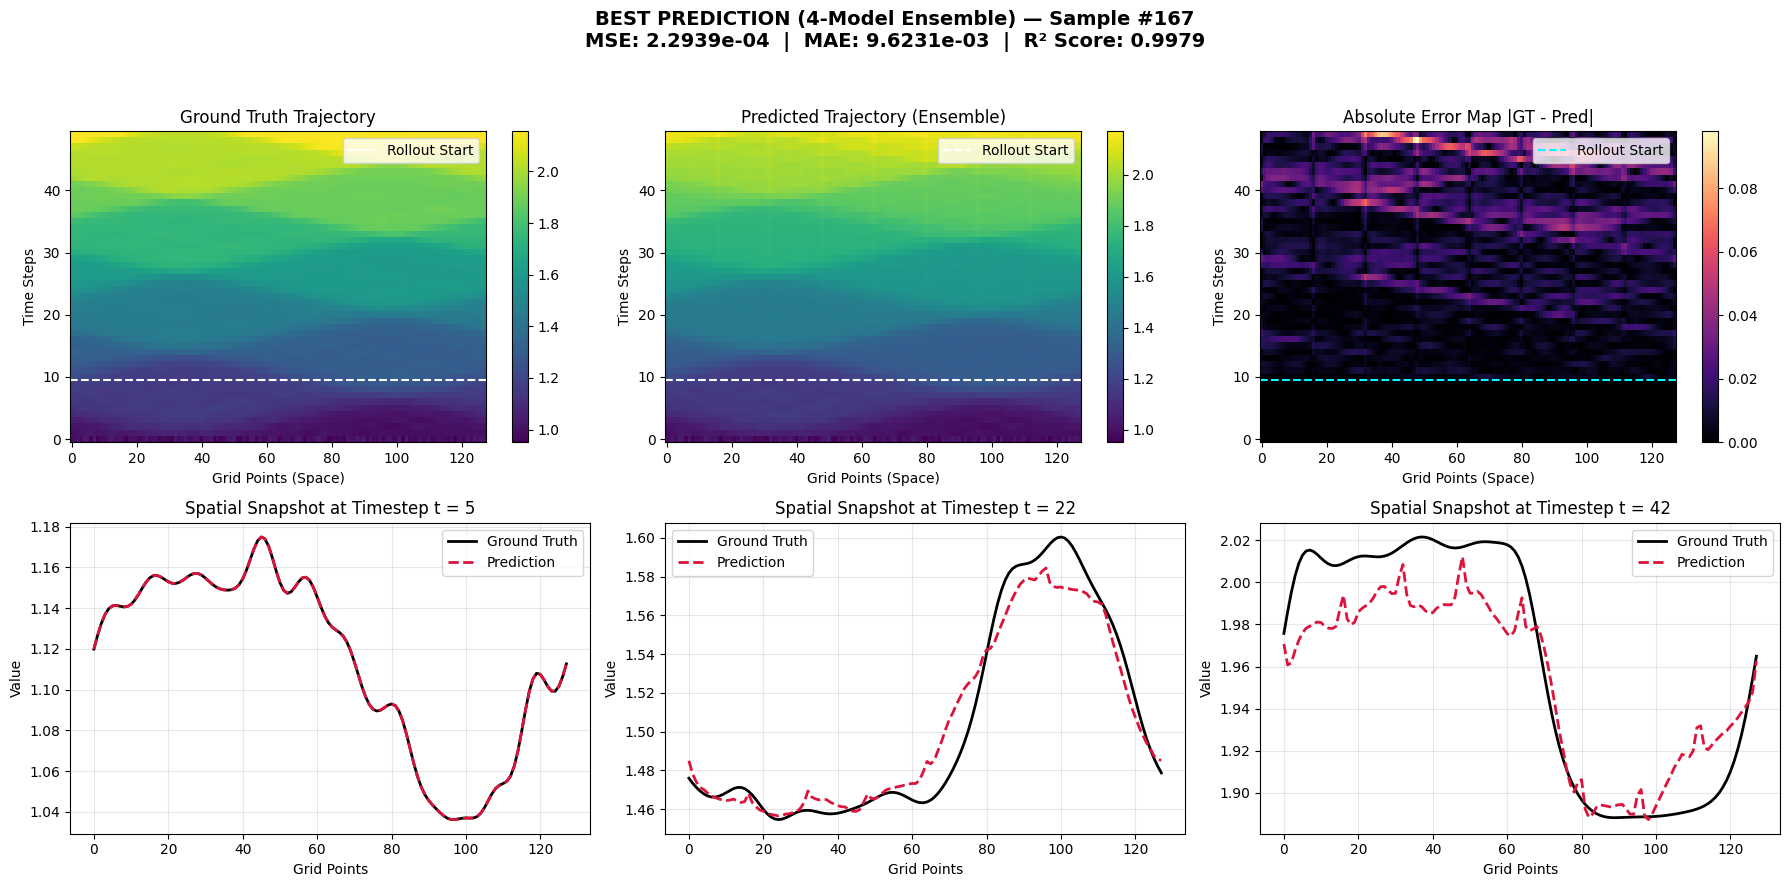

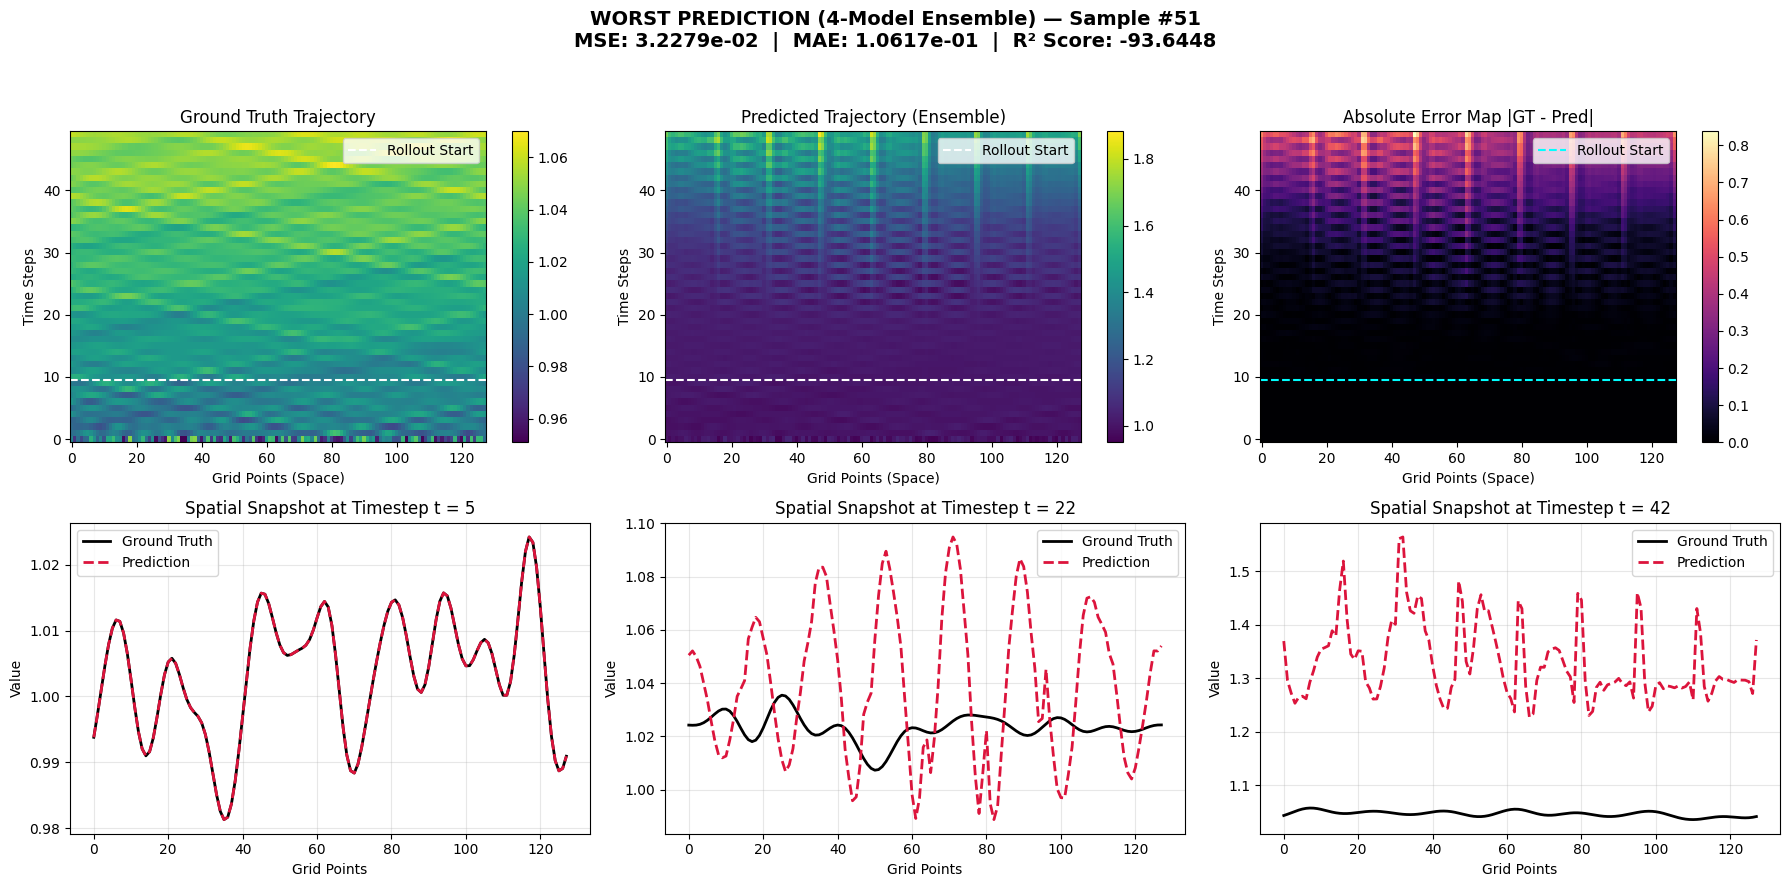

In [8]:

def plot_trajectory_summary(sample_idx, tag, mse, mae, r2, gt_arr, pred_arr, history_steps, grid_points):
    """Plots 2D spatiotemporal heatmaps, error map, and time-slice profile snapshots."""
    gt = gt_arr[sample_idx]
    pred = pred_arr[sample_idx]
    abs_err = np.abs(gt - pred)

    fig = plt.figure(figsize=(18, 9))
    fig.suptitle(
        f"{tag} — Sample #{sample_idx + 1}\n"
        f"MSE: {mse:.4e}  |  MAE: {mae:.4e}  |  R² Score: {r2:.4f}",
        fontsize=14, fontweight='bold', y=0.98
    )

    # 1. Ground Truth Heatmap
    ax1 = plt.subplot(2, 3, 1)
    im1 = ax1.imshow(gt, aspect='auto', cmap='viridis', origin='lower')
    ax1.set_title("Ground Truth Trajectory")
    ax1.set_xlabel("Grid Points (Space)")
    ax1.set_ylabel("Time Steps")
    ax1.axhline(y=history_steps - 0.5, color='white', linestyle='--', linewidth=1.5, label='Rollout Start')
    ax1.legend(loc='upper right')
    plt.colorbar(im1, ax=ax1)

    # 2. Predicted Heatmap
    ax2 = plt.subplot(2, 3, 2)
    im2 = ax2.imshow(pred, aspect='auto', cmap='viridis', origin='lower')
    ax2.set_title("Predicted Trajectory (Ensemble)")
    ax2.set_xlabel("Grid Points (Space)")
    ax2.set_ylabel("Time Steps")
    ax2.axhline(y=history_steps - 0.5, color='white', linestyle='--', linewidth=1.5, label='Rollout Start')
    ax2.legend(loc='upper right')
    plt.colorbar(im2, ax=ax2)

    # 3. Absolute Error Heatmap
    ax3 = plt.subplot(2, 3, 3)
    im3 = ax3.imshow(abs_err, aspect='auto', cmap='magma', origin='lower')
    ax3.set_title("Absolute Error Map |GT - Pred|")
    ax3.set_xlabel("Grid Points (Space)")
    ax3.set_ylabel("Time Steps")
    ax3.axhline(y=history_steps - 0.5, color='cyan', linestyle='--', linewidth=1.5, label='Rollout Start')
    ax3.legend(loc='upper right')
    plt.colorbar(im3, ax=ax3)

    # 4. Spatial Snapshot Profiles across time steps
    t_total = gt.shape[0]
    snapshots = [
        int(history_steps * 0.5),                    # Mid-history
        history_steps + int((t_total - history_steps) * 0.3),  # Early rollout
        history_steps + int((t_total - history_steps) * 0.8)   # Late rollout
    ]

    for i, t_step in enumerate(snapshots):
        ax = plt.subplot(2, 3, 4 + i)
        ax.plot(gt[t_step], label='Ground Truth', color='black', linewidth=2)
        ax.plot(pred[t_step], label='Prediction', color='crimson', linestyle='--', linewidth=2)
        ax.set_title(f"Spatial Snapshot at Timestep t = {t_step}")
        ax.set_xlabel("Grid Points")
        ax.set_ylabel("Value")
        ax.grid(True, alpha=0.3)
        ax.legend()

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()


def main():
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}\n")

    num_pdes = 1000
    time_steps = 50
    grid_points = 128
    history_steps = 10
    ip_time_dim = 10
    channels = 3
    training_amount = int(0.8 * num_pdes)
    num_models = 4
    epochs = 100

    # 1. Dataset Generation & Splitting
    all_pde_data = generate_pde_data(num_pdes, time_steps, grid_points)
    train_data = all_pde_data[:training_amount]
    test_data = all_pde_data[training_amount:]

    X_train, Y_train = prepare_training_pairs(train_data, history_steps=history_steps)
    train_dataset = torch.utils.data.TensorDataset(X_train.to(device), Y_train.to(device).view(-1, 1, 8, 16))
    train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)

    # 2. Train Model Ensemble (with execution timer)
    models = []
    seeds = [42, 123, 456, 789]
    
    print(f"Starting training for {num_models} models ({epochs} epochs each)...")
    start_train_time = time.perf_counter()

    for i in range(num_models):
        model = train_single_model(
            model_idx=i, train_loader=train_loader, epochs=epochs,
            channels=channels, ip_time_dim=ip_time_dim, history_steps=history_steps,
            device=device, seed=seeds[i]
        )
        models.append(model)

    total_train_time = time.perf_counter() - start_train_time
    train_mins, train_secs = divmod(total_train_time, 60)

    # 3. Autoregressive Rollout & Ensembling
    rollout_steps = time_steps - history_steps
    all_model_predictions = []

    print("\nRunning Autoregressive Rollouts...")
    for model in models:
        model.eval()
        current_history = test_data[:, :history_steps, :].permute(0, 2, 1).clone().to(device)
        model_frames = []

        with torch.no_grad():
            for step in range(rollout_steps):
                pred_next = conv_forward_pass_unet(model, current_history, history_steps, ip_time_dim, device)
                pred_1d = pred_next.view(-1, grid_points, 1)  # [batch, 128, 1]
                model_frames.append(pred_1d)

                # Update sliding history window autoregressively for this model
                current_history = torch.cat([current_history[:, :, 1:], pred_1d], dim=2)

        # Concatenate rollout steps along time dim: [batch, grid_points, rollout_steps] -> permute to [batch, rollout_steps, grid_points]
        model_rollout = torch.cat(model_frames, dim=2).permute(0, 2, 1).cpu()
        all_model_predictions.append(model_rollout)

    # 4. Average predictions across the 4 weight variants
    stacked_predictions = torch.stack(all_model_predictions, dim=0)
    ensemble_predictions_only = torch.mean(stacked_predictions, dim=0)  # [batch, rollout_steps, grid_points]

    # Prepend initial ground truth history steps to complete trajectory
    initial_frames = test_data[:, :history_steps, :]
    full_predicted_trajectories = torch.cat([initial_frames, ensemble_predictions_only], dim=1)

    # Print total ensemble training duration
    print(f"\nTotal Training Time for all {num_models} models: {total_train_time:.2f} seconds ({int(train_mins)}m {train_secs:.2f}s)")

    # 5. Evaluate Trajectory Metrics on Ensembled Output
    ground_truth_np = test_data.numpy()
    predicted_np = full_predicted_trajectories.numpy()

    test_mse = np.mean((predicted_np[:, history_steps:, :] - ground_truth_np[:, history_steps:, :]) ** 2)
    print(f"4-Model Ensemble Rollout MSE on {int(0.2 * num_pdes)} Test Trajectories: {test_mse:.4e}")

    mse_per_sample = np.mean((ground_truth_np - predicted_np) ** 2, axis=(1, 2))
    mae_per_sample = np.mean(np.abs(ground_truth_np - predicted_np), axis=(1, 2))

    r2_per_sample = []
    for i in range(len(ground_truth_np)):
        y_true = ground_truth_np[i].flatten()
        y_pred = predicted_np[i].flatten()
        ss_res = np.sum((y_true - y_pred) ** 2)
        ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
        r2 = 1.0 - (ss_res / (ss_tot + 1e-8))
        r2_per_sample.append(r2)
    r2_per_sample = np.array(r2_per_sample)

    best_idx = int(np.argmin(mse_per_sample))
    worst_idx = int(np.argmax(mse_per_sample))

    print(f"Best Test Trajectory Index:  #{best_idx + 1} | MSE: {mse_per_sample[best_idx]:.4e}")
    print(f"Worst Test Trajectory Index: #{worst_idx + 1} | MSE: {mse_per_sample[worst_idx]:.4e}\n")

    # Plot Best & Worst Trajectories
    plot_trajectory_summary(
        best_idx, "BEST PREDICTION (4-Model Ensemble)", 
        mse_per_sample[best_idx], mae_per_sample[best_idx], r2_per_sample[best_idx],
        ground_truth_np, predicted_np, history_steps, grid_points
    )

    plot_trajectory_summary(
        worst_idx, "WORST PREDICTION (4-Model Ensemble)", 
        mse_per_sample[worst_idx], mae_per_sample[worst_idx], r2_per_sample[worst_idx],
        ground_truth_np, predicted_np, history_steps, grid_points
    )


if __name__ == "__main__":
    main()